# EDA de propiedades en venta en CABA

Análisis exploratorio de avisos de casas, departamentos y PH en Capital Federal,
con el objetivo de **preparar un modelo de precio en dólares**.

El notebook cubre:

1. Carga, recorte de calidad y **amenities extraídos de la descripción**
2. **Valores faltantes**
3. **Estadísticas descriptivas** (p10, p25, p50, media, p75, p90)
4. **Distribuciones** (KDE, histogramas)
5. **Outliers**
6. **Relaciones bivariadas** con `precio_usd` (candidatas a predictoras)
7. **Mapa de valores** en CABA
8. **Subte** y su correlación con el precio (mapa de calor + distancia)
9. **Ambientes por barrio** en zona norte


In [1]:
from __future__ import annotations

import json
import re
import unicodedata
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from folium.plugins import HeatMap
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "Data"
GEO_DIR = DATA_DIR / "geo"
GEO_DIR.mkdir(parents=True, exist_ok=True)

csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No hay CSV en {DATA_DIR}")
CSV_PATH = csv_files[0]
print(f"CSV: {CSV_PATH}")


CSV: c:\Users\abril\OneDrive\Documentos\taller IA\Data\casas-departamentos-ph-venta-capital-federal (1).csv


## 1. Carga, calidad mínima y amenities


In [2]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False)
print(f"Filas brutas: {len(df_raw):,}  |  columnas: {df_raw.shape[1]}")
df_raw.head(3)


Filas brutas: 86,700  |  columnas: 50


,id,url,titulo,precio_usd,precio_monto,precio_moneda,precio_texto,precio_min_usd,precio_max_usd,precio_m2_usd,barrio,zona,ciudad,direccion,direccion_visibilidad,latitud,longitud,ambientes,dormitorios,banos,toilettes,cocheras,antiguedad,disposicion,orientacion,luminoso,descripcion,tipo,tipo_publicado,tipo_aviso,superficie_total,superficie_cubierta,superficie_descubierta,superficie_descubierta_origen,superficie_total_texto,superficie_cubierta_texto,superficie_descubierta_texto,expensas,expensas_moneda,anunciante,anunciante_id,tipo_anunciante,fecha_modificacion,reservado,estado,apto_credito,tiene_video,tiene_tour,tiene_planos,fotos
0,20721360,https://www.zonaprop.com.ar/propiedades/clasif...,Venta Dpto Dos Ambientes - Medrano 600 - Almag...,"85,000.00",85000,USD,85.000 USD,NaN,NaN,"2,297.30",Almagro,NaN,Capital Federal,Medrano 600,EXACT,-34.60,-58.42,2.00,1.00,1.00,NaN,NaN,40.00,Contrafrente,NO,Muy luminoso,"Departamento dos ambientes con lavadero, pisos...",departamento,Departamentos,PROPERTY,37.00,37.00,0.00,total_menos_cubierta,37 m²,37 m²,NaN,"7,700.00",$,Vazquez Negocios Inmobiliarios,17054986,inmobiliaria,2026-05-26T00:00:00-0400,no,ONLINE,NaN,no,no,si,8
1,21888364,https://www.zonaprop.com.ar/propiedades/clasif...,"Once., Excelente Depto.2 Amb. 48 m&sup2; con B...","78,500.00",78500,USD,78.500 USD,NaN,NaN,"1,635.42",Once,NaN,Capital Federal,Sarmiento,EXACT,NaN,NaN,2.00,1.00,1.00,NaN,NaN,36.00,Frente,NaN,Muy luminoso,"Sarmiento 2200, entre Pasteur y Uriburu, 5° pi...",departamento,Departamentos,PROPERTY,48.00,43.00,5.00,total_menos_cubierta,48 m²,43 m²,NaN,"72,000.00",$,Paredes Group,17034178,inmobiliaria,2026-10-16T00:00:00-0400,no,ONLINE,si,no,no,no,0
2,23544210,https://www.zonaprop.com.ar/propiedades/clasif...,Venta Monoambiente Ayacucho 400 - Apto Credito...,"78,000.00",78000,USD,78.000 USD,NaN,NaN,"1,950.00",Balvanera,NaN,Capital Federal,Ayacucho 433,EXACT,-34.60,-58.40,1.00,1.00,1.00,NaN,NaN,12.00,Frente,O,Muy luminoso,"Monoambiente al frente, con balcón y mucha luz...",departamento,Departamentos,PROPERTY,40.00,38.00,2.00,total_menos_cubierta,40 m²,38 m²,NaN,"300,000.00",$,Winkel Propiedades,17247566,inmobiliaria,2026-10-19T00:00:00-0400,no,ONLINE,si,no,no,no,11


In [3]:
CABA_LAT = (-34.705, -34.526)
CABA_LON = (-58.531, -58.335)

BARRIOS_NORTE = [
    "Agronomía",
    "Barrio Norte",
    "Belgrano",
    "Chacarita",
    "Coghlan",
    "Colegiales",
    "Núñez",
    "Palermo",
    "Parque Chas",
    "Recoleta",
    "Retiro",
    "Saavedra",
    "Villa Ortuzar",
    "Villa Pueyrredón",
    "Villa Urquiza",
]


def sin_acentos(texto: str) -> str:
    nfkd = unicodedata.normalize("NFKD", str(texto).lower())
    return "".join(ch for ch in nfkd if not unicodedata.combining(ch))


AMENITY_PATTERNS = {
    "jardin": r"jardin(?:es)?",
    "parrilla": r"parrilla(?:s)?",
    "balcon": r"balcon(?:es)?",
    "pileta": r"pileta(?:s)?|piscina(?:s)?|pisicna(?:s)?",
    "sauna": r"sauna(?:s)?",
    "encargado": r"encargad[oa](?:s)?",
    "parquet": r"parquet|entarugad\w*|pinotea",
}


def extraer_amenities(series: pd.Series) -> pd.DataFrame:
    texto = series.fillna("").map(sin_acentos)
    out = {}
    for nombre, patron in AMENITY_PATTERNS.items():
        out[f"amenity_{nombre}"] = texto.str.contains(patron, regex=True).astype("int8")
    return pd.DataFrame(out, index=series.index)


def en_caba(frame: pd.DataFrame) -> pd.Series:
    return (
        frame["latitud"].between(*CABA_LAT)
        & frame["longitud"].between(*CABA_LON)
    )


In [4]:
df = df_raw.copy()
df["precio_usd"] = pd.to_numeric(df["precio_usd"], errors="coerce")
df["precio_m2_usd"] = pd.to_numeric(df["precio_m2_usd"], errors="coerce")

amenities = extraer_amenities(df["descripcion"].astype(str) + " " + df["titulo"].fillna("").astype(str))
df = pd.concat([df, amenities], axis=1)
df["n_amenities"] = df[[c for c in df.columns if c.startswith("amenity_")]].sum(axis=1)

# Recorte para gráficos y correlaciones: deja afuera placeholders (precio 1 USD) y errores de carga.
df["precio_valido"] = (
    df["precio_usd"].between(20_000, 5_000_000)
    & df["precio_moneda"].eq("USD")
)
df["geo_caba"] = en_caba(df)
df["superficie_valida"] = df["superficie_total"].between(15, 2_000)
df["ambientes_validos"] = df["ambientes"].between(1, 10)

print("Amenities (proporción de avisos que los mencionan):")
print(df[[c for c in df.columns if c.startswith("amenity_")]].mean().sort_values(ascending=False))
print()
print(f"Precio válido: {df['precio_valido'].mean():.1%}  |  geo CABA: {df['geo_caba'].mean():.1%}")


Amenities (proporción de avisos que los mencionan):
amenity_balcon      0.60
amenity_parrilla    0.32
amenity_pileta      0.26
amenity_jardin      0.10
amenity_parquet     0.10
amenity_encargado   0.08
amenity_sauna       0.05
dtype: float64

Precio válido: 99.1%  |  geo CABA: 98.5%


Las variables de amenities son **menciones en el texto**, no un inventario del edificio.
Un aviso puede no hablar de pileta aunque el edificio la tenga; al revés, el texto a veces
copia amenities del emprendimiento.


## 2. Valores faltantes


In [5]:
miss = (
    df.isna()
    .mean()
    .mul(100)
    .rename("pct_missing")
    .to_frame()
    .assign(n_missing=df.isna().sum())
    .query("pct_missing > 0")
    .sort_values("pct_missing", ascending=False)
)
miss.head(25)


,pct_missing,n_missing
superficie_descubierta_texto,100.00,86700
precio_max_usd,98.03,84993
precio_min_usd,98.03,84990
zona,87.25,75647
cocheras,75.67,65603
toilettes,70.21,60868
luminoso,53.33,46237
orientacion,49.49,42905
antiguedad,36.74,31854
disposicion,29.48,25555


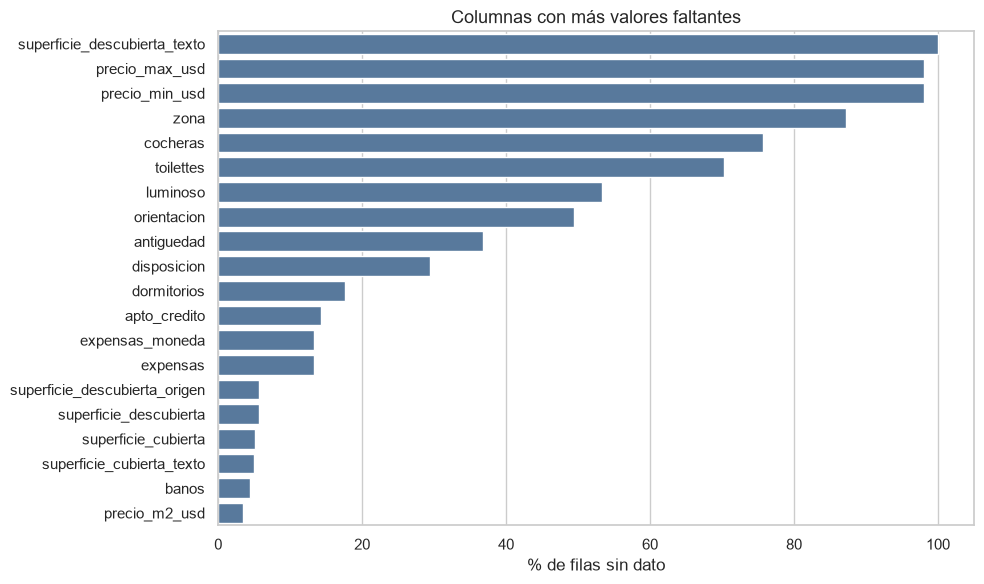

In [6]:
plot_miss = miss.head(20)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=plot_miss["pct_missing"], y=plot_miss.index, ax=ax, color="#4C78A8")
ax.set_xlabel("% de filas sin dato")
ax.set_ylabel("")
ax.set_title("Columnas con más valores faltantes")
plt.tight_layout()
plt.show()


Lectura rápida:

- `zona` falta en ~87% de los avisos: no sirve como predictora global (es un sub-barrio opcional).
- `cocheras` y `toilettes` suelen estar vacíos cuando el aviso no los declara; en muchos casos
  eso equivale a cero, pero no se puede afirmar para todos.
- `antiguedad` falta en ~37%: importante si se usa en un modelo (imputar o indicar “a estrenar” vs desconocido).
- `latitud`/`longitud` faltan poco (~1.3%); hay además coordenadas fuera de CABA.
- `precio_usd` casi completo; los faltantes coinciden sobre todo con avisos en pesos.


## 3. Estadísticas descriptivas (p10, p25, p50, media, p75, p90)


In [7]:
NUMERICAS = [
    "precio_usd",
    "precio_m2_usd",
    "ambientes",
    "dormitorios",
    "banos",
    "toilettes",
    "cocheras",
    "antiguedad",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "expensas",
    "fotos",
    "n_amenities",
]


def descriptivas(frame: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    rows = []
    for col in cols:
        s = pd.to_numeric(frame[col], errors="coerce")
        rows.append(
            {
                "variable": col,
                "n": int(s.notna().sum()),
                "missing_%": 100 * s.isna().mean(),
                "p10": s.quantile(0.10),
                "p25": s.quantile(0.25),
                "p50": s.quantile(0.50),
                "mean": s.mean(),
                "p75": s.quantile(0.75),
                "p90": s.quantile(0.90),
                "min": s.min(),
                "max": s.max(),
            }
        )
    return pd.DataFrame(rows).set_index("variable")


print("Sin recortar outliers:")
desc_raw = descriptivas(df, NUMERICAS)
display(desc_raw)

print("Con precio USD razonable (20 mil a 5 millones):")
desc_ok = descriptivas(df.loc[df["precio_valido"]], NUMERICAS)
display(desc_ok)


Sin recortar outliers:


,n,missing_%,p10,p25,p50,mean,p75,p90,min,max
variable,,,,,,,,,,
precio_usd,86518,0.21,"74,000.00","100,000.00","155,000.00","261,261.02","260,000.00","475,000.00",0.00,"940,000,000.00"
precio_m2_usd,83696,3.46,"1,230.77","1,710.53","2,307.69","2,673.24","3,020.83","3,904.23",0.00,"2,764,705.88"
ambientes,84069,3.03,1.00,2.00,3.00,2.96,4.00,5.00,1.00,"4,096.00"
dormitorios,71417,17.63,1.00,1.00,2.00,2.16,3.00,3.00,1.00,60.00
banos,82910,4.37,1.00,1.00,1.00,1.55,2.00,3.00,1.00,55.00
toilettes,25832,70.21,1.00,1.00,1.00,1.06,1.00,1.00,1.00,11.00
cocheras,21097,75.67,1.00,1.00,1.00,1.45,1.00,2.00,1.00,"1,575.00"
antiguedad,54846,36.74,8.00,20.00,40.00,39.22,52.00,66.00,1.00,999.00
superficie_total,84260,2.81,35.00,46.00,70.00,166.37,119.00,209.00,1.00,"3,121,000.00"


Con precio USD razonable (20 mil a 5 millones):


,n,missing_%,p10,p25,p50,mean,p75,p90,min,max
variable,,,,,,,,,,
precio_usd,85943,0.00,"75,000.00","102,000.00","156,930.00","249,027.62","263,000.00","475,000.00","20,000.00","5,000,000.00"
precio_m2_usd,83585,2.74,"1,235.29","1,712.24","2,307.69","2,638.04","3,020.83","3,902.18",0.14,"1,250,000.00"
ambientes,83409,2.95,1.00,2.00,3.00,2.95,4.00,5.00,1.00,"4,096.00"
dormitorios,70836,17.58,1.00,1.00,2.00,2.15,3.00,3.00,1.00,60.00
banos,82270,4.27,1.00,1.00,1.00,1.54,2.00,3.00,1.00,55.00
toilettes,25491,70.34,1.00,1.00,1.00,1.06,1.00,1.00,1.00,11.00
cocheras,20817,75.78,1.00,1.00,1.00,1.44,1.00,2.00,1.00,"1,575.00"
antiguedad,54491,36.60,8.00,20.00,40.00,39.22,52.00,66.00,1.00,999.00
superficie_total,83585,2.74,35.00,46.00,70.00,165.36,119.00,207.00,1.00,"3,121,000.00"


La **media de `precio_usd` queda muy por encima de la mediana** por avisos con precios
imposibles (incluye valores de 1 USD y cifras de cientos de millones). Para modelar,
conviene recortar o winsorizar; las percentiles (p50 ≈ 155 mil USD en la muestra cruda)
describen mejor el mercado.


## 4. Distribuciones univariadas


In [8]:
CONTINUAS = [
    "precio_usd",
    "precio_m2_usd",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "antiguedad",
    "expensas",
]
DISCRETAS = ["ambientes", "dormitorios", "banos", "toilettes", "cocheras", "fotos", "n_amenities"]
CATEGORICAS = [
    "tipo",
    "disposicion",
    "orientacion",
    "luminoso",
    "tipo_anunciante",
    "apto_credito",
    "reservado",
    "tiene_video",
    "tiene_planos",
]

df_plot = df.loc[df["precio_valido"]].copy()


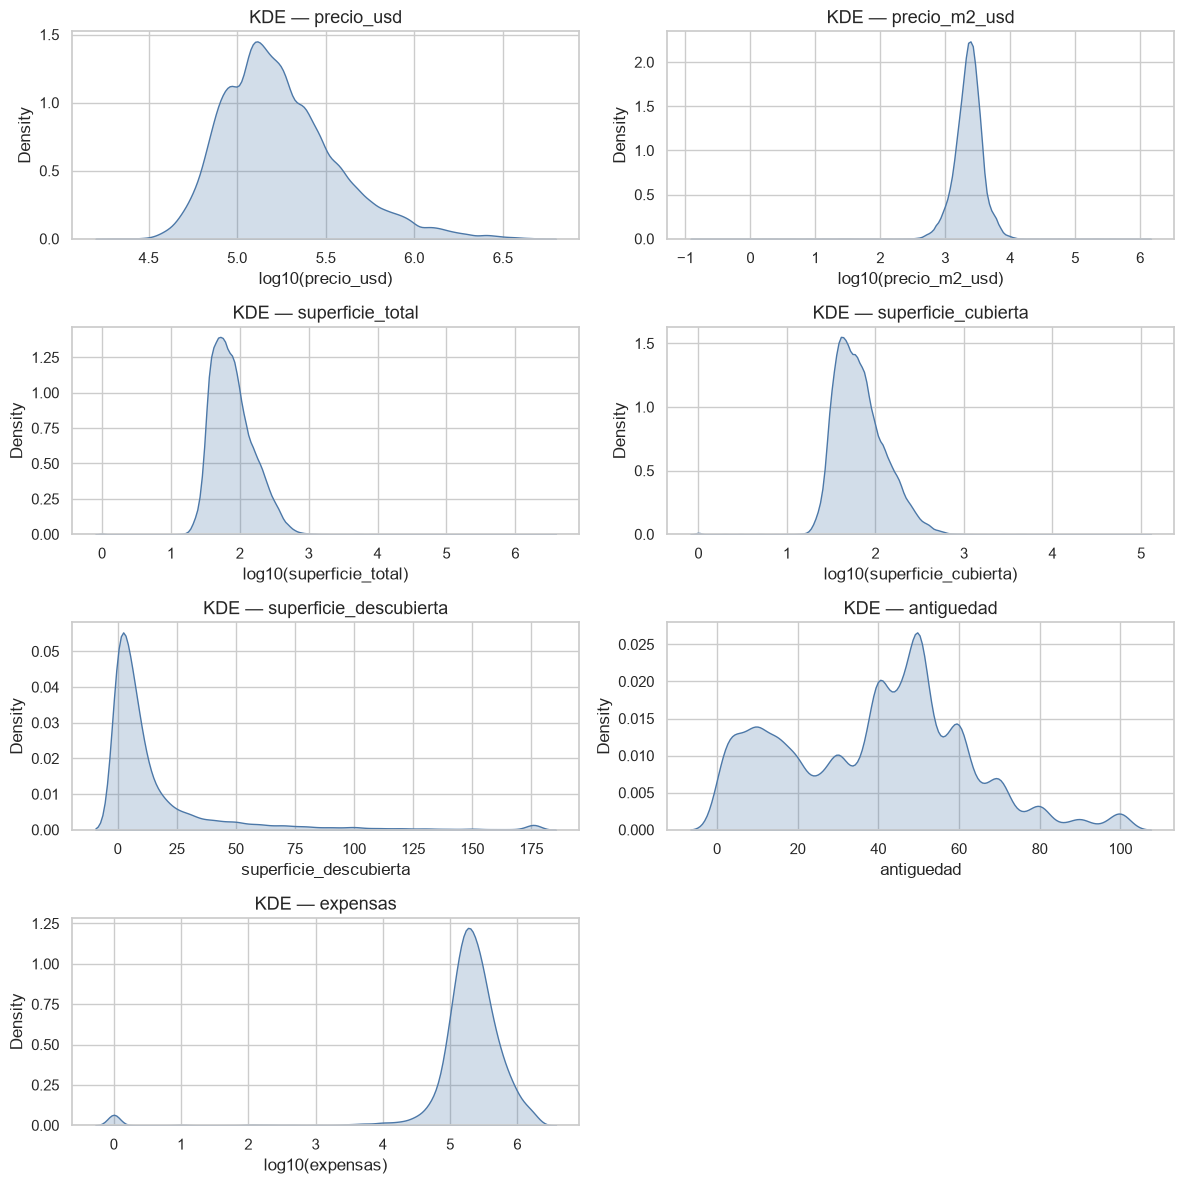

In [9]:
# KDE de continuas (escala log en precio y superficies, que son muy asimétricas).
cont_log = {"precio_usd", "precio_m2_usd", "superficie_total", "superficie_cubierta", "expensas"}
n = len(CONTINUAS)
fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(12, 12))
axes = axes.ravel()
for ax, col in zip(axes, CONTINUAS):
    s = pd.to_numeric(df_plot[col], errors="coerce")
    if col == "expensas":
        s = s.where(s.between(1, 2_000_000))
    elif col in cont_log:
        s = s.where(s > 0)
    s = s.dropna()
    if col in cont_log:
        sns.kdeplot(x=np.log10(s), ax=ax, fill=True, color="#4C78A8")
        ax.set_xlabel(f"log10({col})")
    else:
        sns.kdeplot(x=s.clip(upper=s.quantile(0.99)), ax=ax, fill=True, color="#4C78A8")
        ax.set_xlabel(col)
    ax.set_title(f"KDE — {col}")
for ax in axes[n:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


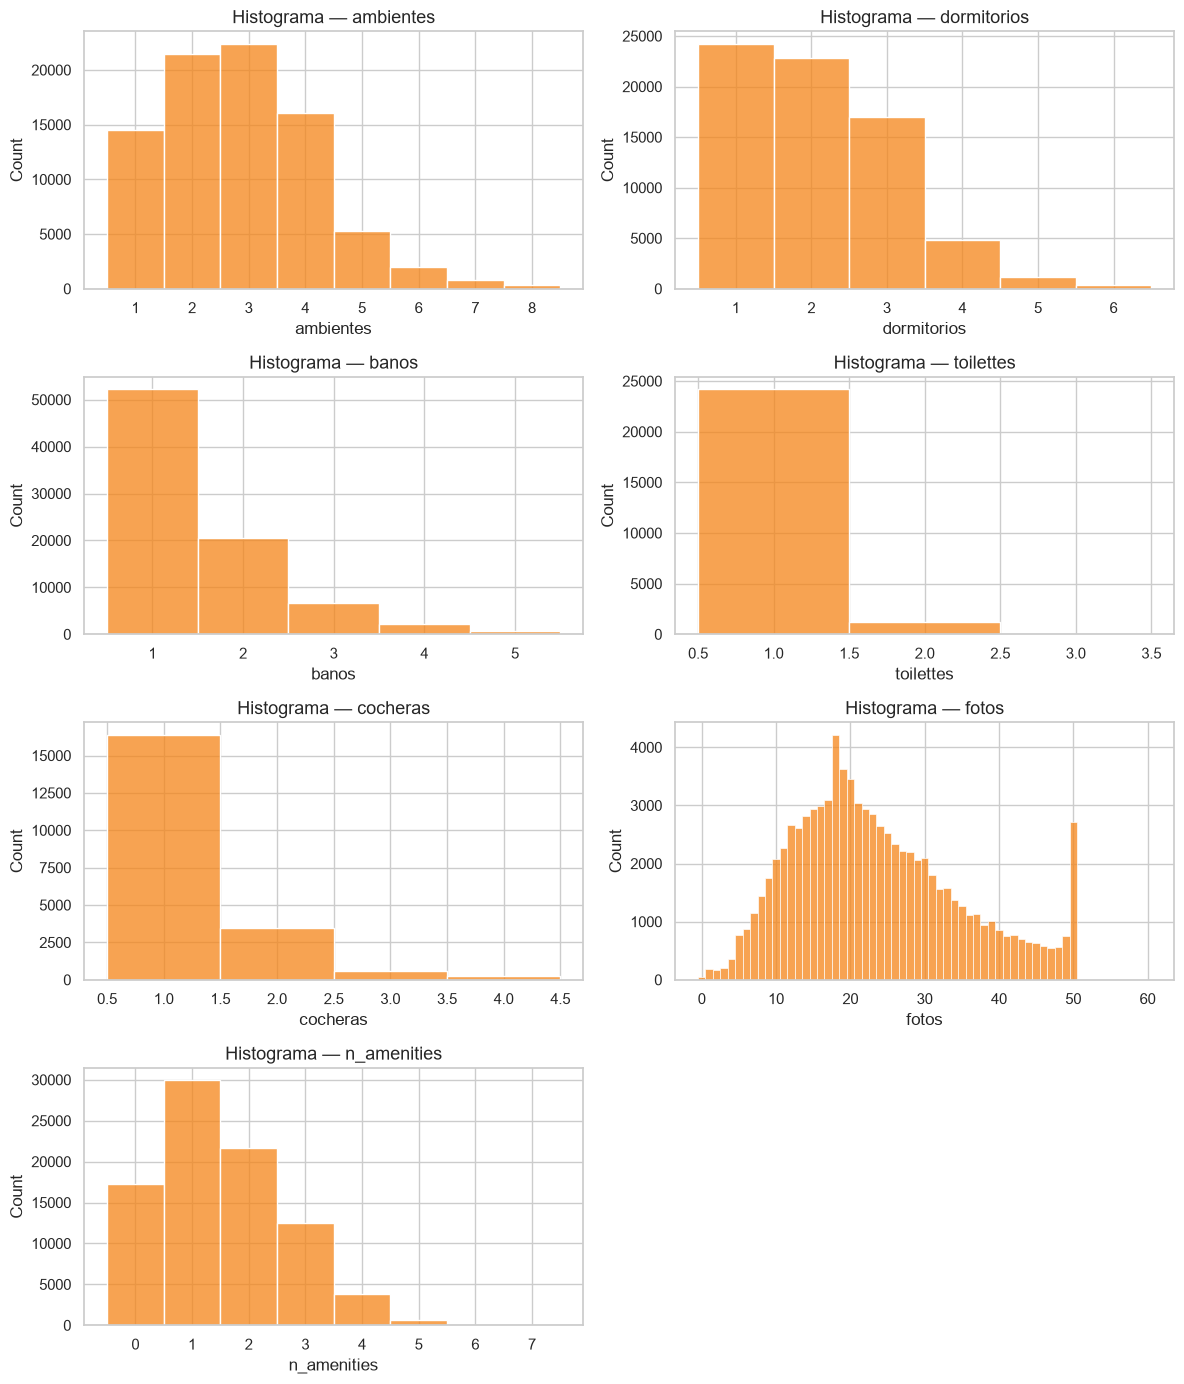

In [10]:
# Histogramas de numéricas discretas (recortadas a rangos creíbles).
clips = {
    "ambientes": (1, 8),
    "dormitorios": (1, 6),
    "banos": (1, 5),
    "toilettes": (1, 3),
    "cocheras": (1, 4),
    "fotos": (0, 60),
    "n_amenities": (0, 7),
}
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
axes = axes.ravel()
for ax, col in zip(axes, DISCRETAS):
    s = pd.to_numeric(df_plot[col], errors="coerce")
    lo, hi = clips[col]
    s = s.dropna()
    s = s[(s >= lo) & (s <= hi)]
    sns.histplot(s, bins=np.arange(lo, hi + 2) - 0.5, ax=ax, color="#F58518")
    ax.set_title(f"Histograma — {col}")
    ax.set_xlabel(col)
for ax in axes[len(DISCRETAS):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


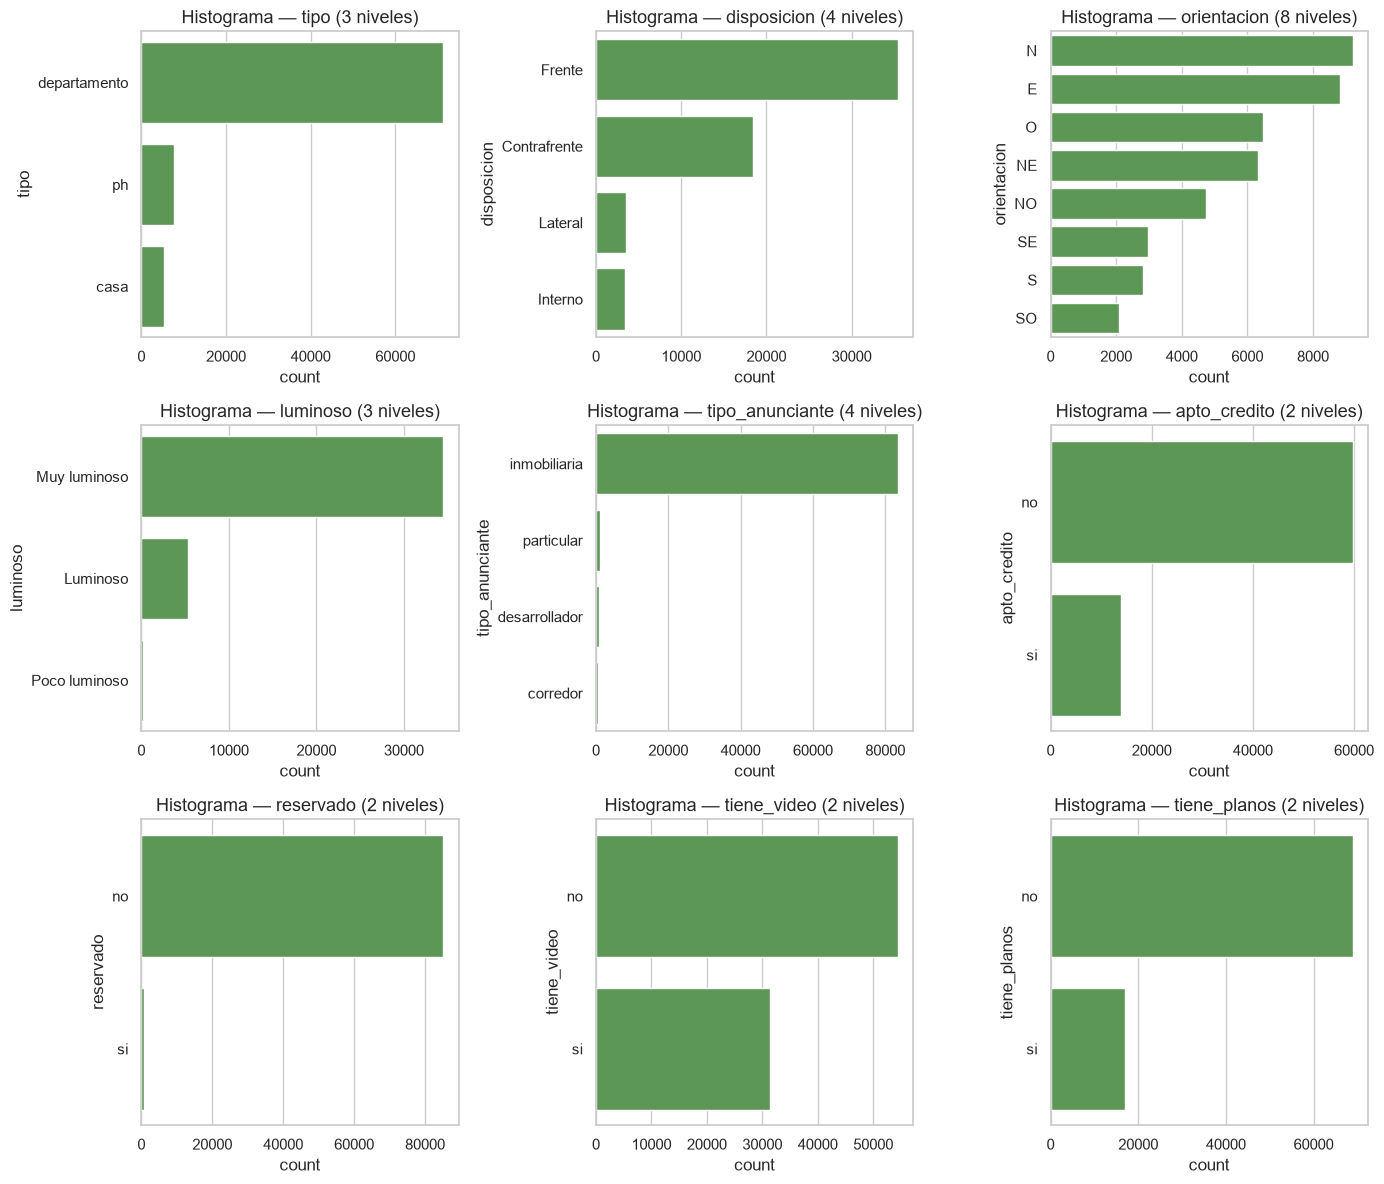

In [11]:
# Histogramas de categóricas con ≤ 10 niveles.
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.ravel()
i = 0
for col in CATEGORICAS:
    ncat = df_plot[col].nunique(dropna=True)
    if ncat == 0 or ncat > 10:
        print(f"Salteo {col}: {ncat} categorías")
        continue
    order = df_plot[col].value_counts().index
    sns.countplot(data=df_plot, y=col, order=order, ax=axes[i], color="#54A24B")
    axes[i].set_title(f"Histograma — {col} ({ncat} niveles)")
    i += 1
for ax in axes[i:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## 5. Outliers


In [12]:
def iqr_outliers(s: pd.Series) -> pd.Series:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


outlier_cols = [
    "precio_usd",
    "precio_m2_usd",
    "superficie_total",
    "ambientes",
    "banos",
    "antiguedad",
    "expensas",
]
rows = []
for col in outlier_cols:
    s = pd.to_numeric(df[col], errors="coerce")
    if col == "expensas":
        s = s.where(s >= 0)
    flag = iqr_outliers(s.dropna())
    rows.append(
        {
            "variable": col,
            "n": int(s.notna().sum()),
            "n_outliers_IQR": int(flag.sum()),
            "pct_IQR": 100 * flag.mean(),
            "p99": s.quantile(0.99),
            "max": s.max(),
        }
    )
pd.DataFrame(rows).set_index("variable")


,n,n_outliers_IQR,pct_IQR,p99,max
variable,,,,,
precio_usd,86518,7707,8.91,"1,700,000.00","940,000,000.00"
precio_m2_usd,83696,3939,4.71,"7,301.68","2,764,705.88"
superficie_total,84260,7004,8.31,498.00,"3,121,000.00"
ambientes,84069,935,1.11,8.00,"4,096.00"
banos,82910,3165,3.82,5.00,55.00
antiguedad,54846,286,0.52,100.00,999.00
expensas,75192,4743,6.31,"1,700,000.00","111,111,002,000,000,000.00"


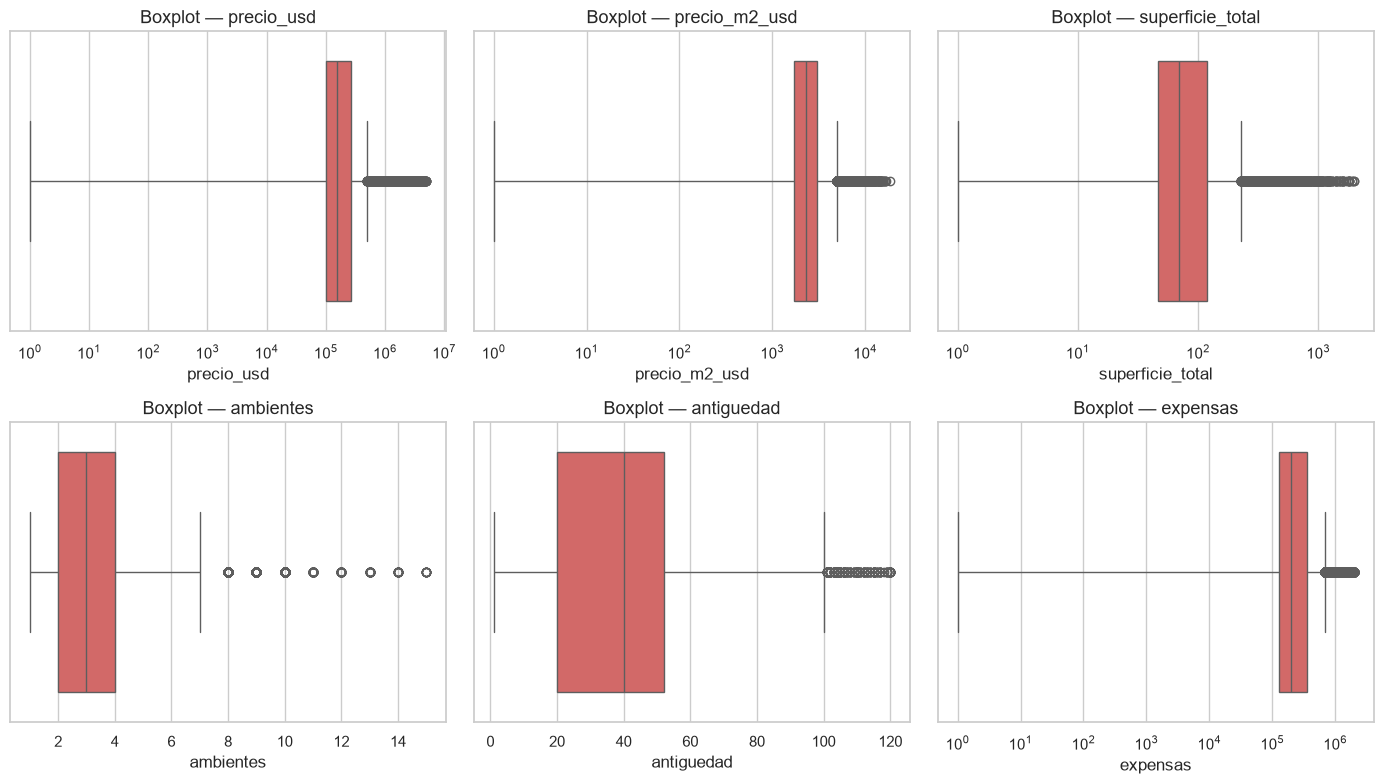

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
box_plan = [
    ("precio_usd", True, df["precio_usd"].between(1, 5_000_000)),
    ("precio_m2_usd", True, df["precio_m2_usd"].between(1, 20_000)),
    ("superficie_total", True, df["superficie_total"].between(1, 2_000)),
    ("ambientes", False, df["ambientes"].between(1, 15)),
    ("antiguedad", False, df["antiguedad"].between(0, 120)),
    ("expensas", True, df["expensas"].between(1, 2_000_000)),
]
for ax, (col, log_y, mask) in zip(axes.ravel(), box_plan):
    s = pd.to_numeric(df.loc[mask, col], errors="coerce").dropna()
    sns.boxplot(x=s, ax=ax, color="#E45756")
    if log_y:
        ax.set_xscale("log")
    ax.set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.show()


Avisos con lat/lon: 85,588  |  fuera del bbox de CABA: 227


,id,barrio,latitud,longitud,precio_usd
35,41368090,Barrio Norte,0.00,0.00,"750,000.00"
90,42808780,Barracas,-38.42,-63.62,"131,000.00"
1232,48904834,Versalles,-29.53,-62.27,"110,000.00"
1242,48930650,Flores,34.09,-118.37,"250,000.00"
1245,48946049,Floresta,-29.14,-59.26,"94,900.00"


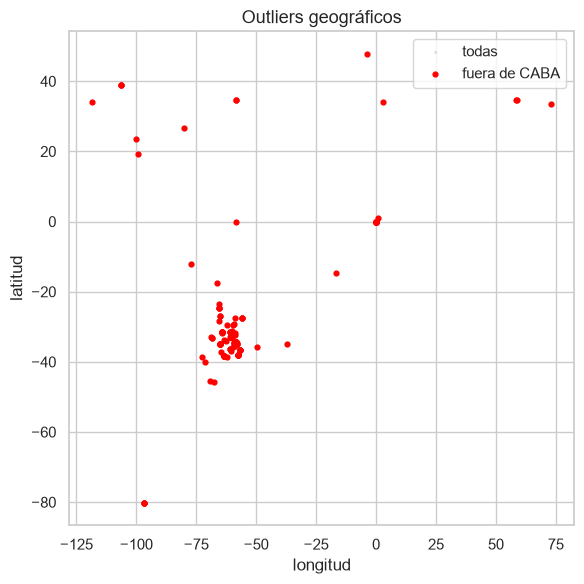

In [14]:
# Coordenadas fuera de CABA (errores de geocodificación).
geo = df.dropna(subset=["latitud", "longitud"])
fuera = geo.loc[~en_caba(geo), ["id", "barrio", "latitud", "longitud", "precio_usd"]]
print(f"Avisos con lat/lon: {len(geo):,}  |  fuera del bbox de CABA: {len(fuera):,}")
display(fuera.head())

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(geo["longitud"], geo["latitud"], s=2, alpha=0.15, c="grey", label="todas")
ax.scatter(fuera["longitud"], fuera["latitud"], s=12, c="red", label="fuera de CABA")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Outliers geográficos")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Precio en USD contra otras variables (predictoras potenciales)


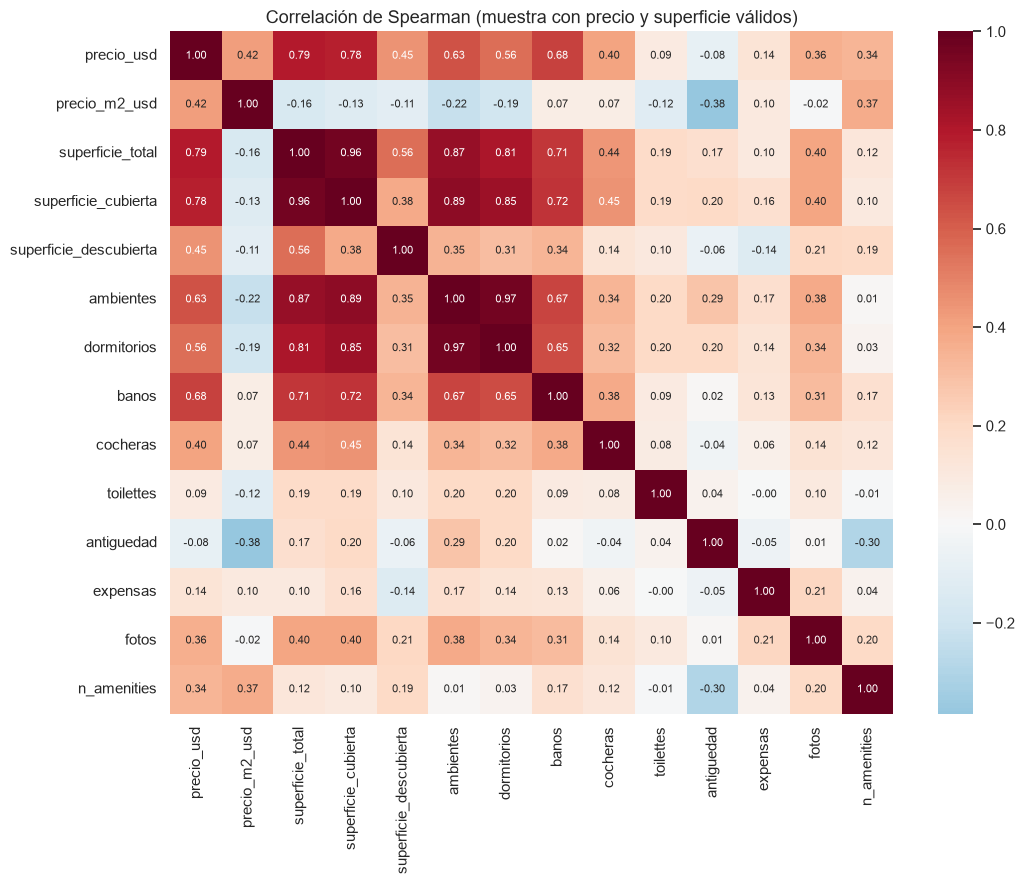

Correlación de Spearman con precio_usd:
superficie_total          0.79
superficie_cubierta       0.78
banos                     0.68
ambientes                 0.63
dormitorios               0.56
superficie_descubierta    0.45
precio_m2_usd             0.42
cocheras                  0.40
fotos                     0.36
n_amenities               0.34
expensas                  0.14
toilettes                 0.09
antiguedad               -0.08
Name: precio_usd, dtype: float64


In [15]:
df_biv = df.loc[
    df["precio_valido"]
    & df["superficie_valida"]
    & df["ambientes_validos"]
].copy()

num_corr = [
    "precio_usd",
    "precio_m2_usd",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "ambientes",
    "dormitorios",
    "banos",
    "cocheras",
    "toilettes",
    "antiguedad",
    "expensas",
    "fotos",
    "n_amenities",
]
corr = df_biv[num_corr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de Spearman (muestra con precio y superficie válidos)")
plt.tight_layout()
plt.show()

print("Correlación de Spearman con precio_usd:")
print(corr["precio_usd"].drop("precio_usd").sort_values(ascending=False))


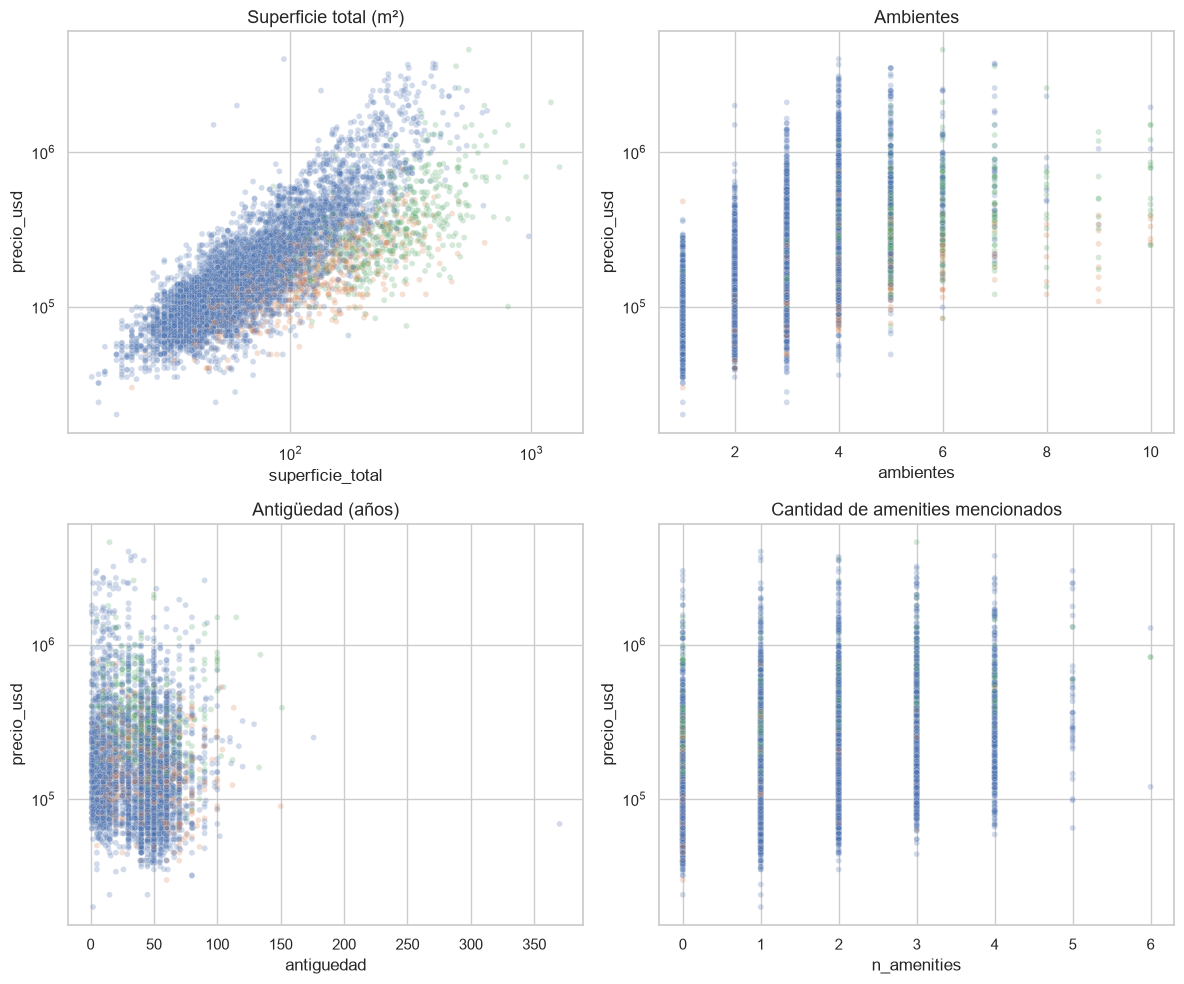

In [16]:
sample = df_biv.sample(n=min(8_000, len(df_biv)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
pares = [
    ("superficie_total", "Superficie total (m²)"),
    ("ambientes", "Ambientes"),
    ("antiguedad", "Antigüedad (años)"),
    ("n_amenities", "Cantidad de amenities mencionados"),
]
for ax, (col, titulo) in zip(axes.ravel(), pares):
    sns.scatterplot(data=sample, x=col, y="precio_usd", hue="tipo", alpha=0.25, s=18, ax=ax, legend=False)
    ax.set_yscale("log")
    if col == "superficie_total":
        ax.set_xscale("log")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()


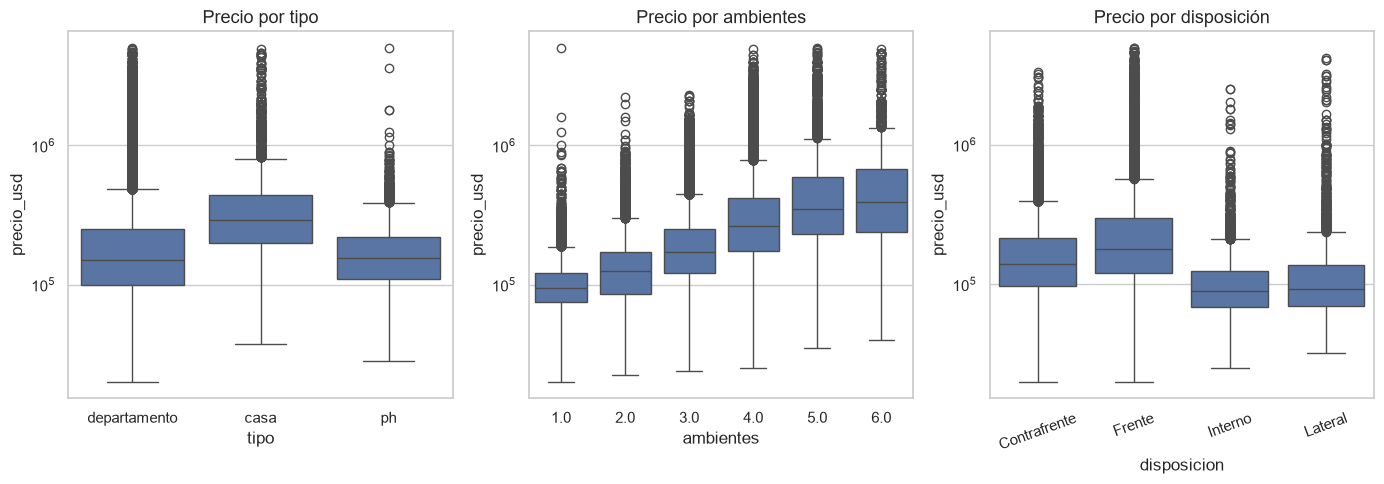

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
sns.boxplot(data=df_biv, x="tipo", y="precio_usd", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Precio por tipo")

sns.boxplot(
    data=df_biv[df_biv["ambientes"] <= 6],
    x="ambientes",
    y="precio_usd",
    ax=axes[1],
)
axes[1].set_yscale("log")
axes[1].set_title("Precio por ambientes")

sns.boxplot(data=df_biv, x="disposicion", y="precio_usd", ax=axes[2])
axes[2].set_yscale("log")
axes[2].tick_params(axis="x", rotation=20)
axes[2].set_title("Precio por disposición")
plt.tight_layout()
plt.show()


,amenity,mediana_sin,mediana_con,ratio_medianas,n_con
4,sauna,"150,800.00","359,000.00",2.38,4095
0,jardin,"149,900.00","269,850.00",1.80,8154
3,pileta,"140,000.00","225,000.00",1.61,21241
1,parrilla,"140,000.00","198,000.00",1.41,25987
2,balcon,"135,000.00","170,000.00",1.26,50277
5,encargado,"157,710.00","155,000.00",0.98,6571
6,parquet,"159,000.00","148,000.00",0.93,8159


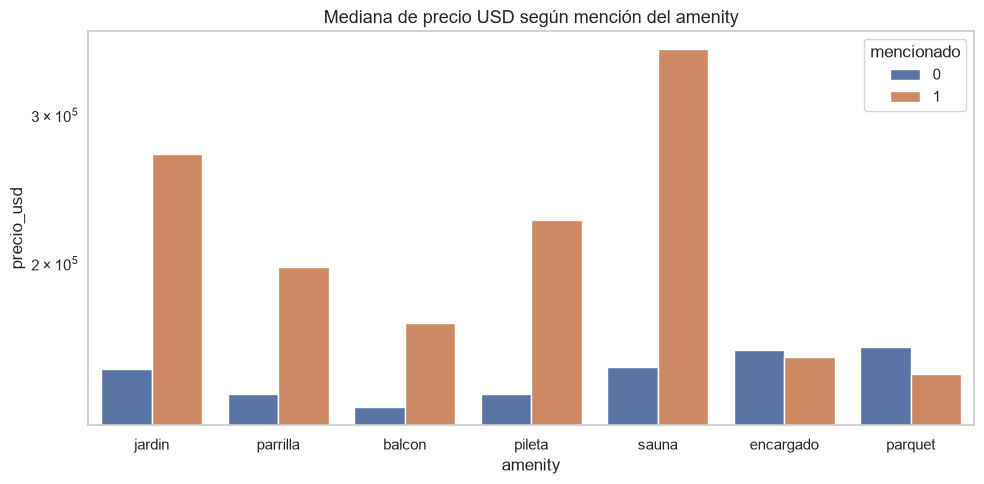

In [18]:
amenity_cols = [c for c in df.columns if c.startswith("amenity_")]
rows = []
for col in amenity_cols:
    g = df_biv.groupby(col)["precio_usd"].agg(["median", "mean", "count"])
    if 0 in g.index and 1 in g.index:
        rows.append(
            {
                "amenity": col.replace("amenity_", ""),
                "mediana_sin": g.loc[0, "median"],
                "mediana_con": g.loc[1, "median"],
                "ratio_medianas": g.loc[1, "median"] / g.loc[0, "median"],
                "n_con": int(g.loc[1, "count"]),
            }
        )
amenity_precio = pd.DataFrame(rows).sort_values("ratio_medianas", ascending=False)
display(amenity_precio)

fig, ax = plt.subplots(figsize=(10, 5))
melted = df_biv.melt(
    id_vars=["precio_usd"],
    value_vars=amenity_cols,
    var_name="amenity",
    value_name="tiene",
)
melted["amenity"] = melted["amenity"].str.replace("amenity_", "", regex=False)
sns.barplot(
    data=melted,
    x="amenity",
    y="precio_usd",
    hue="tiene",
    estimator=np.median,
    errorbar=None,
    ax=ax,
)
ax.set_yscale("log")
ax.set_title("Mediana de precio USD según mención del amenity")
ax.legend(title="mencionado")
plt.tight_layout()
plt.show()


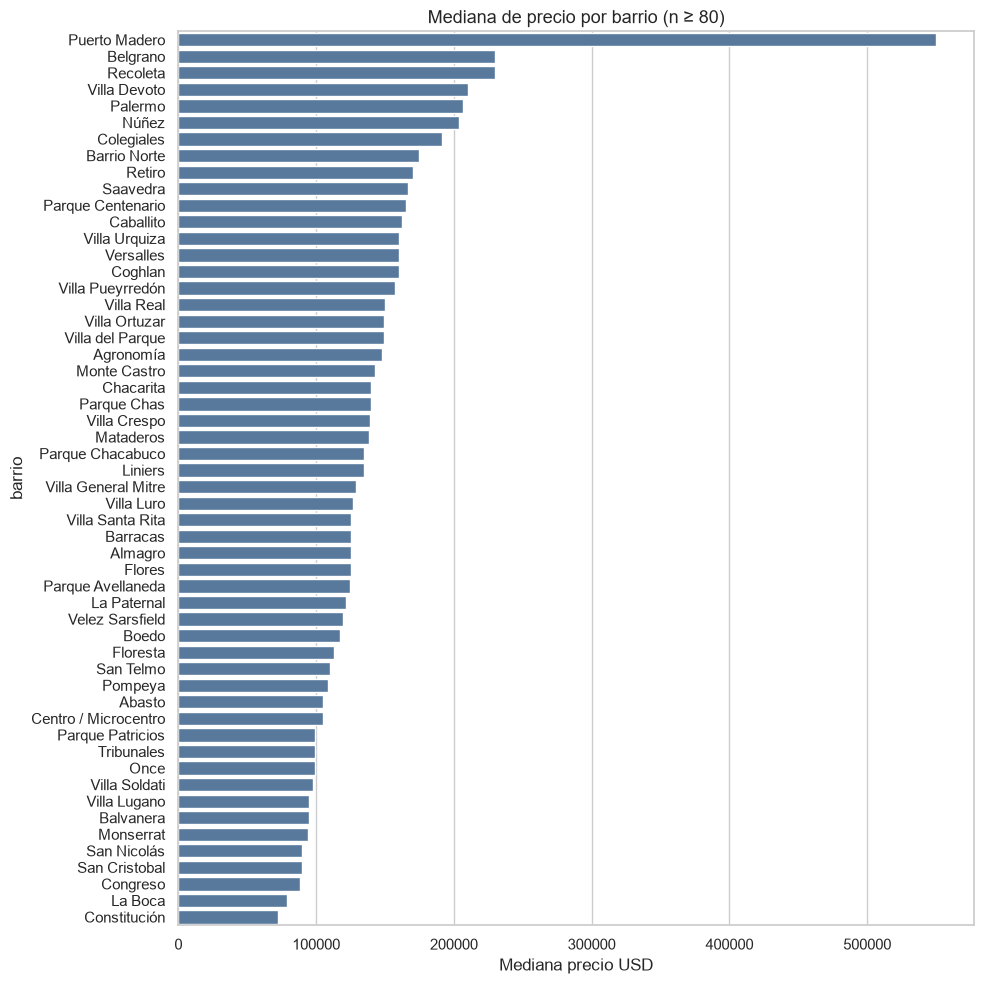

,n,mediana,p90
barrio,,,
Puerto Madero,1760,"550,000.00","1,650,000.00"
Belgrano,6566,"230,000.00","795,000.00"
Recoleta,5618,"230,000.00","650,000.00"
Villa Devoto,2353,"210,000.00","550,000.00"
Palermo,11885,"206,688.00","751,500.00"
Núñez,3118,"204,000.00","650,000.00"
Colegiales,1572,"191,190.00","549,999.90"
Barrio Norte,1614,"174,950.00","470,000.00"
Retiro,1191,"170,000.00","660,000.00"


In [19]:
barrio_stats = (
    df_biv.groupby("barrio")
    .agg(n=("precio_usd", "size"), mediana=("precio_usd", "median"), p90=("precio_usd", lambda s: s.quantile(0.9)))
    .query("n >= 80")
    .sort_values("mediana", ascending=False)
)
fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(data=barrio_stats.reset_index(), y="barrio", x="mediana", ax=ax, color="#4C78A8")
ax.set_xlabel("Mediana precio USD")
ax.set_title("Mediana de precio por barrio (n ≥ 80)")
plt.tight_layout()
plt.show()
barrio_stats.head(15)


Candidatas fuertes a predictoras (Spearman y gráficos):

- **superficie_cubierta / total**, **ambientes**, **baños**, **dormitorios**
- **barrio** (y, en menor medida, tipo)
- **amenities** de pileta, sauna, parquet, encargado (correlacionados también con zona y categoría del edificio)
- **antigüedad** (relación más débil y no lineal: a estrenar vs. usado)

`precio_m2_usd` no debería entrar como predictora de `precio_usd` si se construye con el mismo precio.


## 7. Mapa de CABA: valores de las propiedades


In [20]:
BARRIOS_URL = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/barrios/barrios.geojson"
SUBTE_URL = "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-estaciones/estaciones-de-subte.csv"
BARRIOS_PATH = GEO_DIR / "barrios.geojson"
SUBTE_PATH = GEO_DIR / "estaciones-de-subte.csv"


def descargar(url: str, path: Path) -> Path:
    if path.exists() and path.stat().st_size > 0:
        return path
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    path.write_bytes(r.content)
    print(f"Descargado {path} ({path.stat().st_size:,} bytes)")
    return path


descargar(BARRIOS_URL, BARRIOS_PATH)
descargar(SUBTE_URL, SUBTE_PATH)

barrios_geo = json.loads(BARRIOS_PATH.read_text(encoding="utf-8"))
print(f"Barrios en el geojson: {len(barrios_geo['features'])}")


Barrios en el geojson: 48


In [21]:
df_map = df.loc[df["precio_valido"] & df["geo_caba"]].copy()


def clave_barrio(nombre: str) -> str:
    t = sin_acentos(nombre).replace("villa ", "villa ")
    alias = {
        "barrio norte": "recoleta",
        "centro / microcentro": "san nicolas",
        "congreso": "balvanera",
        "once": "balvanera",
        "abasto": "balvanera",
        "tribunales": "san nicolas",
        "parque centenario": "caballito",
        "agronomia": "agronomia",
        "constitucion": "constitucion",
        "san cristobal": "san cristobal",
        "velez sarsfield": "velez sarsfield",
        "villa pueyrredon": "villa pueyrredon",
        "nunez": "nunez",
        "villa del parque": "villa del parque",
        "villa gral. mitre": "villa general mitre",
        "villa general mitre": "villa general mitre",
        "nueva pompeya": "nueva pompeya",
        "pompeya": "nueva pompeya",
        "otro": "",
    }
    t = t.strip()
    return alias.get(t, t)


df_map["barrio_clave"] = df_map["barrio"].map(clave_barrio)
for feat in barrios_geo["features"]:
    feat["properties"]["barrio_clave"] = clave_barrio(feat["properties"]["nombre"])

mediana_barrio = (
    df_map.groupby("barrio_clave")["precio_usd"]
    .median()
    .rename("mediana_usd")
    .reset_index()
)
print(mediana_barrio.sort_values("mediana_usd", ascending=False).head(10))


     barrio_clave  mediana_usd
27  puerto madero   550,000.00
0                   323,500.00
5        belgrano   230,000.00
28       recoleta   211,000.00
38   villa devoto   210,000.00
22        palermo   205,000.00
21          nunez   200,000.00
10     colegiales   190,000.00
29         retiro   171,250.00
30       saavedra   165,000.00


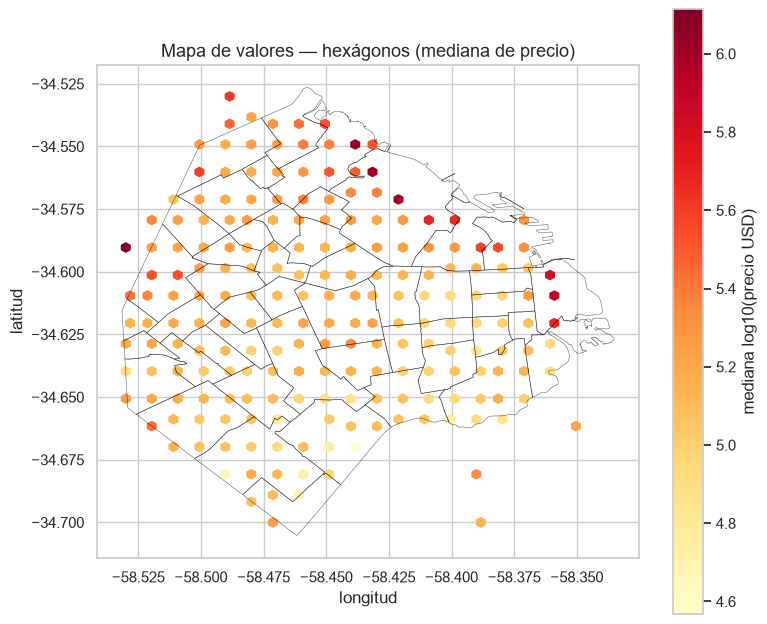

In [22]:
# Hexbin estático: densidad de valor (mediana de log precio por celda).
fig, ax = plt.subplots(figsize=(8, 9))
hb = ax.hexbin(
    df_map["longitud"],
    df_map["latitud"],
    C=np.log10(df_map["precio_usd"]),
    reduce_C_function=np.median,
    gridsize=55,
    cmap="YlOrRd",
    mincnt=3,
)
for feat in barrios_geo["features"]:
    geom = feat["geometry"]
    polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    for poly in polys:
        xs, ys = zip(*poly[0])
        ax.plot(xs, ys, color="black", linewidth=0.4, alpha=0.6)
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label("mediana log10(precio USD)")
ax.set_title("Mapa de valores — hexágonos (mediana de precio)")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [23]:
centro = [-34.61, -58.44]
mapa_valores = folium.Map(location=centro, zoom_start=12, tiles="cartodbpositron")
folium.Choropleth(
    geo_data=barrios_geo,
    data=mediana_barrio,
    columns=["barrio_clave", "mediana_usd"],
    key_on="feature.properties.barrio_clave",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.5,
    nan_fill_color="lightgrey",
    legend_name="Mediana precio USD por barrio",
).add_to(mapa_valores)
folium.LayerControl().add_to(mapa_valores)
mapa_valores


c:\Users\abril\OneDrive\Documentos\taller IA\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 8. Subte y precio: mapa de calor y distancia a la estación más cercana


In [24]:
subte = pd.read_csv(SUBTE_PATH, sep=";", encoding="utf-8", encoding_errors="replace")
subte.columns = [c.strip().lstrip("﻿") for c in subte.columns]
subte["longitud"] = subte["long"].astype(str).str.replace(",", ".", regex=False).astype(float)
subte["latitud"] = subte["lat"].astype(str).str.replace(",", ".", regex=False).astype(float)
print(subte[["estacion", "linea", "latitud", "longitud"]].head())
print(subte["linea"].value_counts())


                     estacion linea  latitud  longitud
0                     CASEROS     H   -34.64    -58.40
1  INCLAN - MEZQUITA AL AHMAD     H   -34.63    -58.40
2                HUMBERTO 1Â°     H   -34.62    -58.40
3                   VENEZUELA     H   -34.62    -58.40
4      ONCE - 30 DE DICIEMBRE     H   -34.61    -58.41
linea
A    18
E    18
B    17
D    16
H    12
C     9
Name: count, dtype: int64


In [25]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


lat_p = df_map["latitud"].to_numpy()
lon_p = df_map["longitud"].to_numpy()
lat_s = subte["latitud"].to_numpy()
lon_s = subte["longitud"].to_numpy()

# Distancia a cada estación (n_avisos x n_estaciones).
dist = haversine_km(lat_p[:, None], lon_p[:, None], lat_s[None, :], lon_s[None, :])
idx_min = dist.argmin(axis=1)
df_map = df_map.copy()
df_map["dist_subte_km"] = dist.min(axis=1)
df_map["estacion_cercana"] = subte["estacion"].to_numpy()[idx_min]
df_map["linea_cercana"] = subte["linea"].to_numpy()[idx_min]

print(df_map["dist_subte_km"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print("Spearman precio vs distancia al subte:",
      df_map[["precio_usd", "dist_subte_km"]].corr(method="spearman").iloc[0, 1])
print("Spearman precio_m2 vs distancia al subte:",
      df_map[["precio_m2_usd", "dist_subte_km"]].corr(method="spearman").iloc[0, 1])


count   84,643.00
mean         1.07
std          1.16
min          0.09
10%          0.21
25%          0.36
50%          0.66
75%          1.25
90%          2.78
max          7.98
Name: dist_subte_km, dtype: float64
Spearman precio vs distancia al subte: 0.11284866984660248
Spearman precio_m2 vs distancia al subte: -0.03876949437905111


In [26]:
# Heatmap de precios + estaciones de subte.
heat_sample = df_map.sample(n=min(25_000, len(df_map)), random_state=42)
heat_data = list(
    zip(
        heat_sample["latitud"],
        heat_sample["longitud"],
        np.log10(heat_sample["precio_usd"]),
    )
)

LINE_COLORS = {
    "A": "#00adcb",
    "B": "#e03a3e",
    "C": "#0067b0",
    "D": "#008166",
    "E": "#6b238e",
    "H": "#ffd200",
}

mapa_subte = folium.Map(location=centro, zoom_start=12, tiles="cartodbpositron")
HeatMap(
    heat_data,
    radius=14,
    blur=18,
    min_opacity=0.35,
    max_zoom=16,
    name="Calor de log(precio USD)",
).add_to(mapa_subte)

for linea, grupo in subte.groupby("linea"):
    fg = folium.FeatureGroup(name=f"Línea {linea}")
    color = LINE_COLORS.get(str(linea).strip().upper(), "black")
    for _, row in grupo.iterrows():
        folium.CircleMarker(
            location=[row["latitud"], row["longitud"]],
            radius=5,
            color=color,
            fill=True,
            fill_opacity=0.95,
            tooltip=f"{row['estacion']} (línea {linea})",
        ).add_to(fg)
    fg.add_to(mapa_subte)

folium.LayerControl().add_to(mapa_subte)
mapa_subte


c:\Users\abril\OneDrive\Documentos\taller IA\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


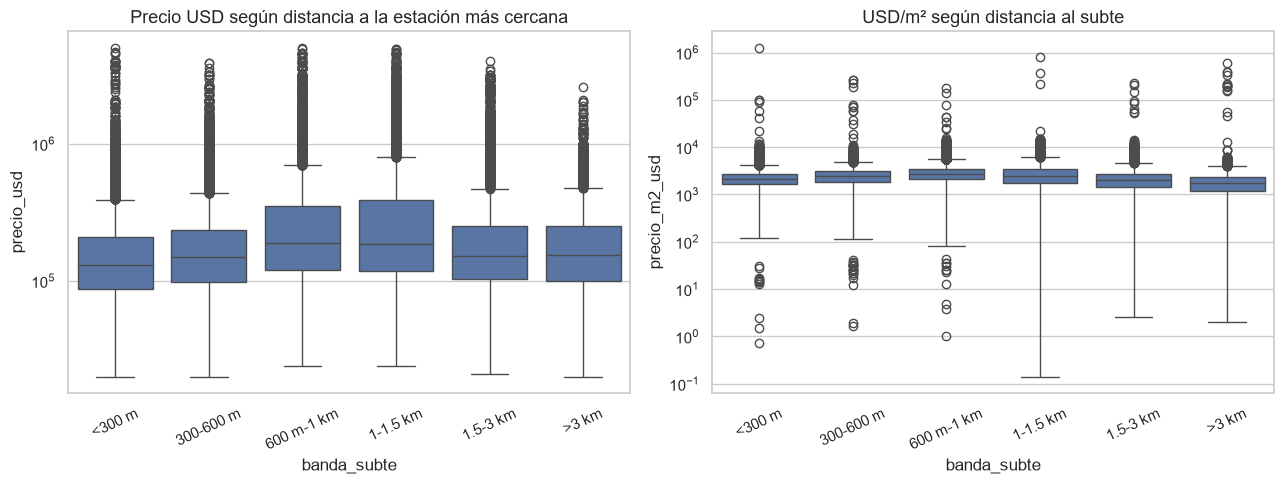

,n,mediana_usd,mediana_m2
banda_subte,,,
<300 m,18263,"131,500.00","2,100.00"
300-600 m,20516,"149,500.00","2,422.99"
600 m-1 km,20741,"190,000.00","2,727.27"
1-1.5 km,7052,"185,000.00","2,500.00"
1.5-3 km,10990,"153,000.00","2,037.04"
>3 km,7081,"155,000.00","1,756.76"


In [27]:
df_map["banda_subte"] = pd.cut(
    df_map["dist_subte_km"],
    bins=[0, 0.3, 0.6, 1.0, 1.5, 3.0, 20],
    labels=["<300 m", "300-600 m", "600 m-1 km", "1-1.5 km", "1.5-3 km", ">3 km"],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_map, x="banda_subte", y="precio_usd", ax=axes[0])
axes[0].set_yscale("log")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_title("Precio USD según distancia a la estación más cercana")

sns.boxplot(data=df_map, x="banda_subte", y="precio_m2_usd", ax=axes[1])
axes[1].set_yscale("log")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_title("USD/m² según distancia al subte")
plt.tight_layout()
plt.show()

display(
    df_map.groupby("banda_subte", observed=True).agg(
        n=("precio_usd", "size"),
        mediana_usd=("precio_usd", "median"),
        mediana_m2=("precio_m2_usd", "median"),
    )
)


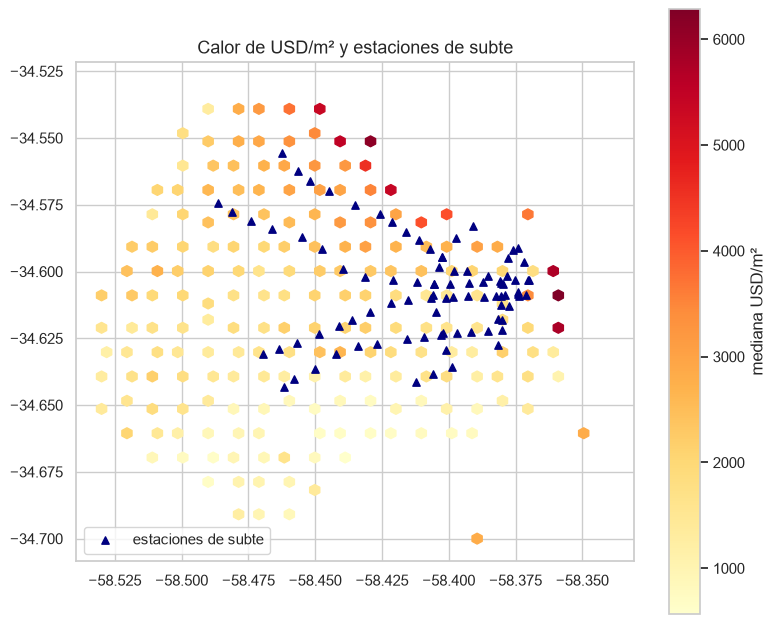

In [28]:
fig, ax = plt.subplots(figsize=(8, 9))
hb = ax.hexbin(
    df_map["longitud"],
    df_map["latitud"],
    C=df_map["precio_m2_usd"],
    reduce_C_function=np.median,
    gridsize=50,
    cmap="YlOrRd",
    mincnt=4,
)
ax.scatter(
    subte["longitud"],
    subte["latitud"],
    s=28,
    c="navy",
    marker="^",
    label="estaciones de subte",
    zorder=3,
)
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label("mediana USD/m²")
ax.set_title("Calor de USD/m² y estaciones de subte")
ax.legend(loc="lower left")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


La correlación precio–distancia al subte suele ser **negativa pero moderada**: estar más
cerca de una estación se asocia a precios (y sobre todo USD/m²) más altos, pero el efecto
se mezcla con el barrio (Palermo/Recoleta ya son caros y están bien servidos; el sur también
tiene subte y precios más bajos). Para un modelo, `dist_subte_km` es una candidata útil
**junto con barrio**, no en lugar de barrio.


## 9. Ambientes por barrio en zona norte


In [29]:
norte = df.loc[
    df["barrio"].isin(BARRIOS_NORTE)
    & df["precio_valido"]
    & df["ambientes_validos"]
].copy()
print(f"Avisos zona norte: {len(norte):,}")
print(norte["barrio"].value_counts())

tabla = (
    norte.assign(ambientes=norte["ambientes"].astype(int))
    .pivot_table(
        index="barrio",
        columns="ambientes",
        values="id",
        aggfunc="count",
        fill_value=0,
    )
)
# Porcentaje de fila para comparar barrios de distinto tamaño.
tabla_pct = tabla.div(tabla.sum(axis=1), axis=0) * 100
display(tabla)


Avisos zona norte: 39,875
barrio
Palermo             11976
Belgrano             6600
Recoleta             5681
Villa Urquiza        3309
Núñez                3130
Barrio Norte         1622
Colegiales           1588
Saavedra             1468
Retiro               1202
Villa Pueyrredón      902
Coghlan               653
Villa Ortuzar         597
Chacarita             580
Parque Chas           381
Agronomía             186
Name: count, dtype: int64


ambientes,1,2,3,4,5,6,7,8,9,10
barrio,,,,,,,,,,
Agronomía,33,50,43,42,7,4,3,3,0,1
Barrio Norte,310,370,406,365,118,26,12,4,9,2
Belgrano,1083,1583,1617,1538,483,188,73,19,7,9
Chacarita,153,194,145,43,30,7,3,4,0,1
Coghlan,157,176,158,91,41,18,7,3,0,2
Colegiales,254,393,482,318,95,34,7,3,1,1
Núñez,626,955,889,497,109,32,13,3,4,2
Palermo,2592,3347,2750,2248,694,184,94,37,18,12
Parque Chas,94,90,104,59,23,5,4,2,0,0


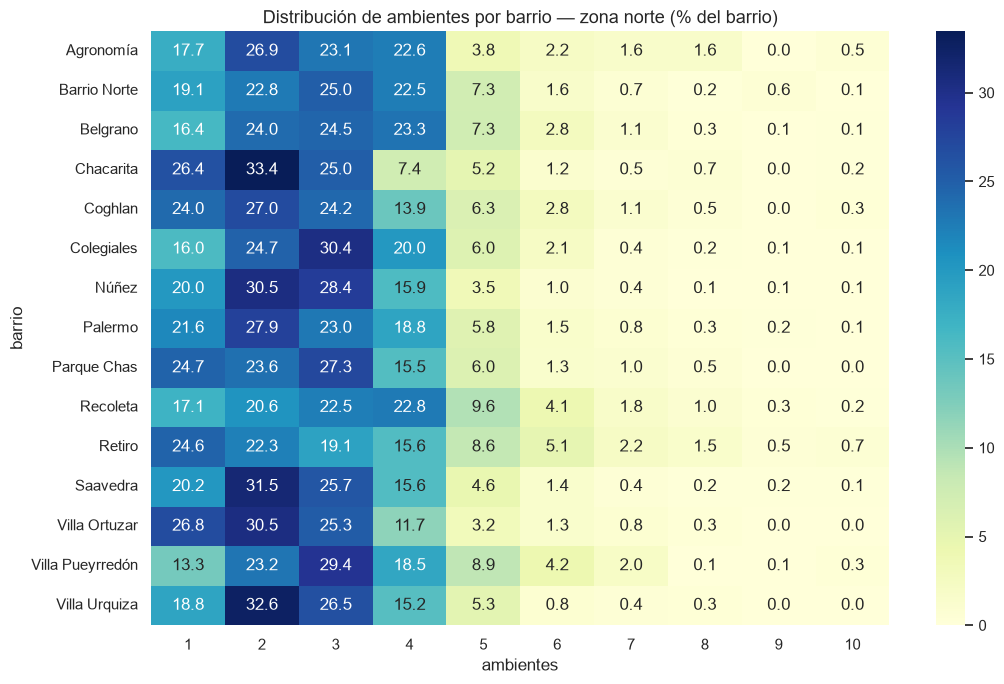

In [30]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(tabla_pct, cmap="YlGnBu", annot=True, fmt=".1f", ax=ax)
ax.set_title("Distribución de ambientes por barrio — zona norte (% del barrio)")
ax.set_xlabel("ambientes")
plt.tight_layout()
plt.show()


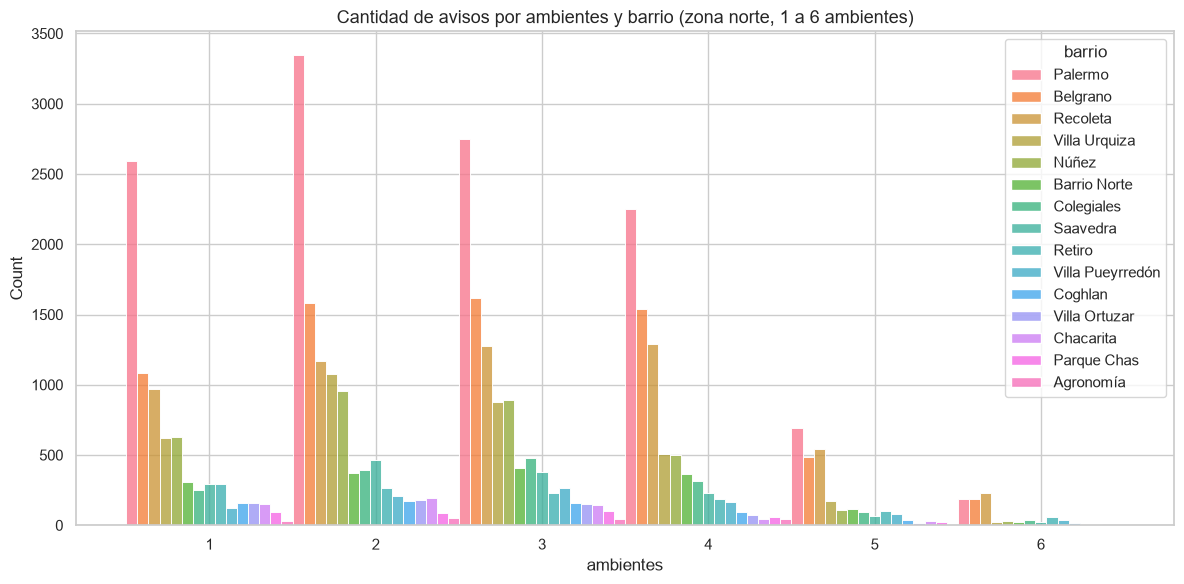

In [31]:
fig, ax = plt.subplots(figsize=(12, 6))
order = norte["barrio"].value_counts().index
sns.histplot(
    data=norte[norte["ambientes"] <= 6],
    x="ambientes",
    hue="barrio",
    hue_order=order,
    multiple="dodge",
    discrete=True,
    ax=ax,
)
ax.set_title("Cantidad de avisos por ambientes y barrio (zona norte, 1 a 6 ambientes)")
plt.tight_layout()
plt.show()


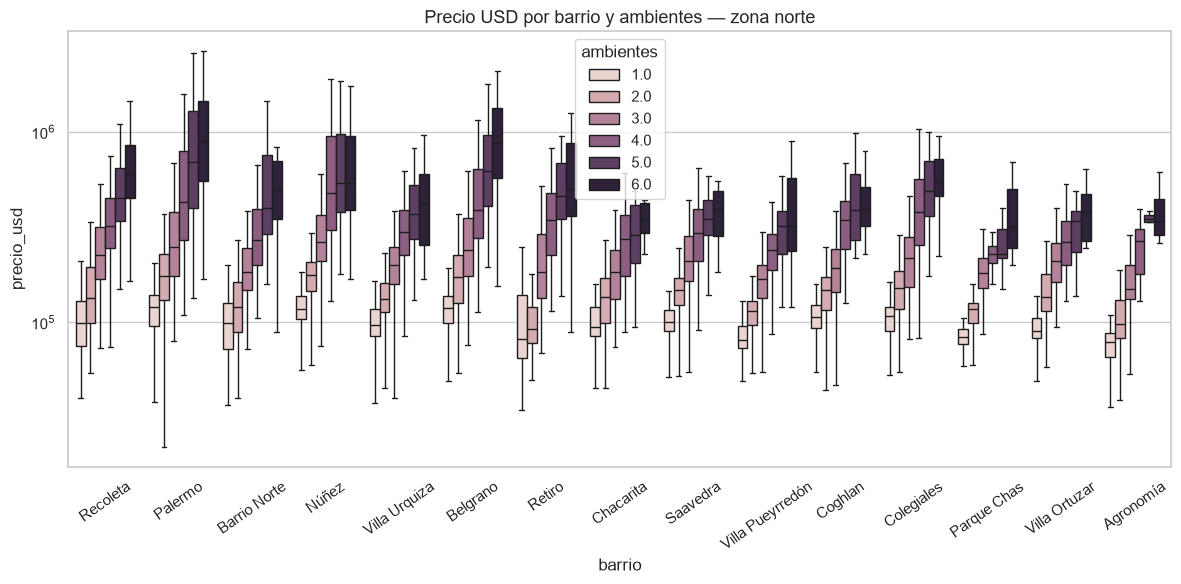

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=norte[norte["ambientes"] <= 6],
    x="barrio",
    y="precio_usd",
    hue="ambientes",
    ax=ax,
    showfliers=False,
)
ax.set_yscale("log")
ax.tick_params(axis="x", rotation=35)
ax.set_title("Precio USD por barrio y ambientes — zona norte")
plt.tight_layout()
plt.show()


## 10. Implicancias para el modelo de precio

- **Target:** `precio_usd` (filtrar moneda USD y un rango creíble; log-precio como transformación).
- **Estructura:** superficie (cubierta y total), ambientes, baños, tipo, barrio.
- **Texto:** amenities binarias; pileta/sauna/parquet/encargado separan bien la mediana.
- **Espacio:** coordenadas CABA o distancia al subte; el mapa muestra un gradiente norte/este vs. sur/oeste.
- **Cuidado:** outliers de superficie, ambientes 4096, expensas disparatadas, precio = 1, lat/lon fuera de CABA.
- **Missing:** antiguedad, disposición, cocheras; `zona` no es recuperable para la mayoría.

Próximo paso de modelado (fuera de este notebook): un recorte de calidad, dummies de barrio/tipo
e amenities, y una baseline de regresión sobre `log(precio_usd)`.
